# 🤖 Proyek Machine Learning: Online Shoppers Purchasing Intention (prediksi pengunjung toko online jadi beli atau tidak)

**Nama:** Farisa Nadhira El-fansyah 

**NIM:** 241011402466

**Kelas:** 05TPLP023

**Mata Kuliah:** Machine Learning

**Sumber dataset:** https://archive.ics.uci.edu/dataset/468  |  **Jumlah data:** 12.330 baris

---

| No | Tahap | Isi |
|----|-------|-----|
| 1 | Import Library | pandas, numpy, matplotlib, seaborn, sklearn |
| 2 | Data Loading | `read_csv`, `head()` |
| 3 | Informasi Data | `info()`, `shape`, `describe()`, `unique()`, `value_counts()` |
| 4 | Data Cleaning | missing value, outlier (IQR), duplikasi |
| 5 | Transformasi | one-hot encoding & label encoding |
| 6 | EDA | histogram, korelasi, heatmap |
| 7 | Data Splitting | `train_test_split` |
| 8 | Normalisasi / Standardisasi | `StandardScaler` (setelah split, agar tidak data leakage) |
| 9 | Modelling | beberapa algoritma |
| 10 | Evaluasi | MAE/MSE/R² (regresi) atau Accuracy/Precision/Recall/F1 (klasifikasi) |
| 11 | Cross Validation | `cross_val_score` |
| 12 | Simpan Model | `joblib` & `pickle` |
| 13 | Kesimpulan | |


In [1]:
!pip install ucimlrepo
import pandas as pd
from ucimlrepo import fetch_ucirepo

d = fetch_ucirepo(id=468)
df = pd.concat([d.data.features, d.data.targets], axis=1)
df.to_csv("online_shoppers_intention.csv", index=False)
print(df.shape)
print(df.columns.tolist())


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


(12330, 18)
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']


## ⚙️ 0. Konfigurasi 

FILE_PATH = "online_shoppers_intention.csv"

TARGET = "Revenue"

TASK = "auto"

DROP_COLS = []

OUTLIER_METHOD = "tidak"

## 1. Import Library

- **pandas** → mengolah data dalam bentuk tabel (DataFrame)
- **numpy** → operasi numerik
- **matplotlib & seaborn** → visualisasi
- **scikit-learn (sklearn)** → preprocessing, model, dan evaluasi

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

FILE_PATH = "online_shoppers_intention.csv"
TARGET = "Revenue"
TASK = "auto"
DROP_COLS = []
MISSING_THRESHOLD = 0.75
OUTLIER_METHOD = "tidak"
CORR_THRESHOLD = 0.0
TEST_SIZE = 0.2
RANDOM_STATE = 1

## 2. Data Loading

Dataset dimuat ke dalam **DataFrame** pandas. Fungsi yang dipakai sesuai format file:

| Format | Fungsi |
|--------|--------|
| CSV | `pd.read_csv()` |
| Excel | `pd.read_excel()` |
| SQL | `pd.read_sql()` |

`.head()` menampilkan 5 baris pertama untuk memastikan data berhasil dimuat.

In [5]:
if FILE_PATH.lower().endswith((".xlsx", ".xls")):
    df_raw = pd.read_excel(FILE_PATH)
else:
    df_raw = pd.read_csv(FILE_PATH)

assert TARGET in df_raw.columns, f"Kolom target '{TARGET}' tidak ditemukan. Pilih salah satu: {list(df_raw.columns)}"
print(f"Dataset berhasil dimuat: {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
if df_raw.shape[0] < 1000:
    print("⚠️ Peringatan: jumlah data < 1000 baris (syarat tugas minimal 1000).")
df_raw.head()

Dataset berhasil dimuat: 12330 baris, 18 kolom


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 3. Menampilkan Informasi Data

Dilakukan untuk mengetahui isi dataset: nama fitur/kolom, tipe data, dan dimensi data.
Tujuan pemeriksaan tipe data adalah memastikan semuanya sudah sesuai (contoh kesalahan: data numerik terbaca sebagai string).

Keyword yang dipakai:
- `.info()` → ringkasan kolom, tipe data, dan jumlah non-null
- `.shape` → ukuran data (baris, kolom)
- `.describe()` → statistik deskriptif (mean, median, std, min, max)
- `.unique()` / `.nunique()` → nilai unik pada kolom
- `.value_counts()` → frekuensi kemunculan nilai

In [6]:
# Ringkasan informasi dataset
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  str    
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType              12330 no

In [7]:
# Dimensi data (baris, kolom)
print("Dimensi data :", df_raw.shape)
print("Jumlah baris :", df_raw.shape[0])
print("Jumlah kolom :", df_raw.shape[1])

Dimensi data : (12330, 18)
Jumlah baris : 12330
Jumlah kolom : 18


In [8]:
# Statistik deskriptif seluruh kolom (numerik & kategorikal)
df_raw.describe(include="all")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462,10422
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN,NaN


In [9]:
# Jumlah nilai unik di setiap kolom
df_raw.nunique().sort_values(ascending=False)

ProductRelated_Duration    9551
ExitRates                  4777
Administrative_Duration    3335
PageValues                 2704
BounceRates                1872
Informational_Duration     1258
ProductRelated              311
Administrative               27
TrafficType                  20
Informational                17
Browser                      13
Month                        10
Region                        9
OperatingSystems              8
SpecialDay                    6
VisitorType                   3
Weekend                       2
Revenue                       2
dtype: int64

In [10]:
# Nilai unik & frekuensi pada kolom kategorikal (maks. 10 nilai teratas per kolom)
for col in df_raw.select_dtypes(exclude=["number"]).columns:
    print(f"--- {col} ({df_raw[col].nunique()} nilai unik) ---")
    print(df_raw[col].value_counts(dropna=False).head(10))
    print()

--- Month (10 nilai unik) ---
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

--- VisitorType (3 nilai unik) ---
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

--- Weekend (2 nilai unik) ---
Weekend
False    9462
True     2868
Name: count, dtype: int64

--- Revenue (2 nilai unik) ---
Revenue
False    10422
True      1908
Name: count, dtype: int64



### 3.1 Menentukan jenis kasus (regresi / klasifikasi)

- **Regresi** → target berupa angka kontinu (misal harga rumah). Model: Linear Regression, Gradient Boosting Regressor, dll.
- **Klasifikasi** → target berupa kategori (misal lulus/tidak). Model: Decision Tree, Logistic Regression, Random Forest, dll.

Kolom target : Revenue
Jenis kasus  : KLASIFIKASI

Distribusi kelas target:
Revenue
False    10422
True      1908
Name: count, dtype: int64


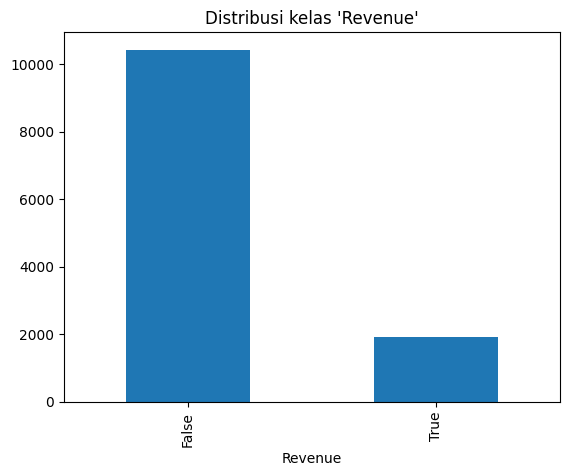

In [11]:
if TASK == "auto":
    if pd.api.types.is_numeric_dtype(df_raw[TARGET]) and df_raw[TARGET].nunique() > 15:
        TASK = "regresi"
    else:
        TASK = "klasifikasi"

print("Kolom target :", TARGET)
print("Jenis kasus  :", TASK.upper())
print()
if TASK == "klasifikasi":
    print("Distribusi kelas target:")
    print(df_raw[TARGET].value_counts(dropna=False))
    df_raw[TARGET].value_counts().plot(kind="bar", title=f"Distribusi kelas '{TARGET}'")
    plt.show()
else:
    sns.histplot(df_raw[TARGET].dropna(), kde=True)
    plt.title(f"Distribusi target '{TARGET}'")
    plt.show()

## 4. Data Cleaning

> *"Garbage In – Garbage Out"*: jika input buruk, hasil model pasti buruk. Hal yang diperhatikan: **konsistensi format, skala data, duplikasi, missing value, dan skewness**.

Agar data asli tidak berubah (dan bisa dibandingkan sebelum/sesudah), kita bekerja pada salinan bernama `df`.

### 4.1 Menghapus kolom yang tidak relevan

Kolom seperti ID, nama, atau kolom kosong tidak membantu model belajar. Isi `DROP_COLS` di cell konfigurasi.
Kolom `Unnamed: ...` (biasanya sisa kolom kosong dari Excel/CSV) dibuang otomatis.

In [12]:
df = df_raw.copy()

# buang kolom 'Unnamed' (kolom kosong bawaan file)
unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]
df = df.drop(columns=unnamed)

# buang kolom tidak relevan pilihan kita
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns])

# data tanpa target tidak bisa dipakai belajar -> buang barisnya
df = df.dropna(subset=[TARGET])

# kolom bertipe boolean diubah ke 0/1
bool_cols = df.select_dtypes(include="bool").columns
df[bool_cols] = df[bool_cols].astype(int)

# Petunjuk: kolom kategorikal yang nilainya hampir unik di setiap baris (mis. nama/ID) biasanya tidak berguna
for c in df.select_dtypes(exclude=["number", "bool"]).columns:
    if c != TARGET and df[c].nunique() > 0.9 * len(df):
        print(f"💡 Kolom '{c}' hampir unik di tiap baris (kemungkinan ID/nama). Pertimbangkan masukkan ke DROP_COLS.")

print("Dimensi setelah langkah ini:", df.shape)

Dimensi setelah langkah ini: (12330, 18)


### 4.2 Memeriksa Missing Value

Missing value terjadi saat data sebuah record tidak lengkap, dan sangat memengaruhi performa model. Ada 2 opsi:
1. **Menghapus** data/kolom yang missing, atau
2. **Mengisi** dengan nilai lain: *mean*, *median* (numerik) atau *modus* (kategorikal).

In [13]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = df.isnull().sum()
missing_pct = (missing_values / len(df)) * 100

missing_data = pd.DataFrame({"Missing Values": missing_values, "Percentage": missing_pct}) \
                 .sort_values(by="Missing Values", ascending=False)
missing_data[missing_data["Missing Values"] > 0]

,Missing Values,Percentage


### 4.3 Mengatasi Missing Value

Kolom dipisah menjadi dua kelompok sesuai batas `MISSING_THRESHOLD` (75%):
- **`less`** → kolom dengan missing sedikit → **diisi**: numerik dengan **median**, kategorikal dengan **modus**.
- **`over`** → kolom dengan missing terlalu banyak → **dihapus**.

In [14]:
missing_ratio = df.isnull().mean()
less = missing_ratio[missing_ratio < MISSING_THRESHOLD].index
over = missing_ratio[missing_ratio >= MISSING_THRESHOLD].index
print("Kolom yang akan dihapus (missing >= batas):", list(over))

# a) Isi nilai hilang pada kolom NUMERIK dengan median
numeric_fill = df[less].select_dtypes(include=["number"]).columns
df[numeric_fill] = df[numeric_fill].fillna(df[numeric_fill].median())

# b) Isi nilai hilang pada kolom KATEGORIKAL dengan modus (nilai paling sering muncul)
kategorical_features = df[less].select_dtypes(exclude=["number", "bool"]).columns
for column in kategorical_features:
    df[column] = df[column].fillna(df[column].mode()[0])

# c) Hapus kolom dengan terlalu banyak missing value
df = df.drop(columns=over)

# Verifikasi
missing_values = df.isnull().sum()
print("Sisa kolom yang masih missing:")
print(missing_values[missing_values > 0])
print("Dimensi data:", df.shape)

Kolom yang akan dihapus (missing >= batas): []
Sisa kolom yang masih missing:
Series([], dtype: int64)
Dimensi data: (12330, 18)


### 4.4 Mengatasi Outlier (metode IQR)

Outlier adalah nilai yang jauh berbeda dari nilai lainnya dan bisa mengacaukan model. Langkah metode **IQR (Interquartile Range)**:
1. Hitung `Q1` (persentil 25) dan `Q3` (persentil 75), lalu `IQR = Q3 - Q1`
2. Batas bawah = `Q1 - 1.5 × IQR`, batas atas = `Q3 + 1.5 × IQR`
3. Nilai di luar batas = outlier → **dihapus** (atau diganti nilai batas)

> Catatan: kolom **target** dan kolom yang hanya punya ≤ 10 nilai unik (biner/diskret, mis. 0/1) tidak diperiksa outlier-nya agar kelas/kategori tidak ikut terhapus.

Fitur numerik       : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']
Dicek outlier       : ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'Browser', 'TrafficType']


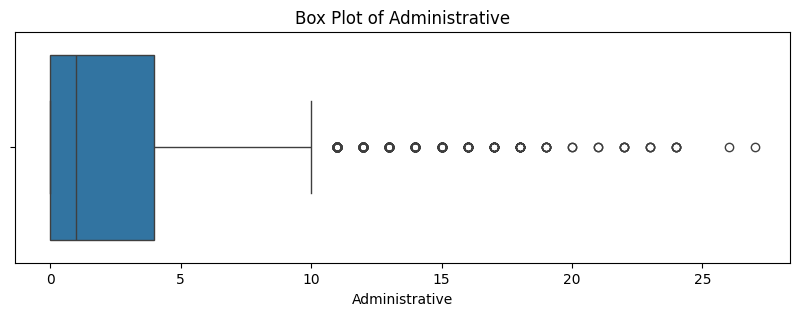

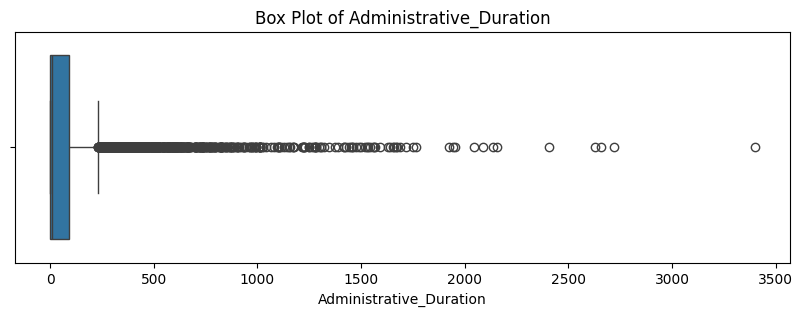

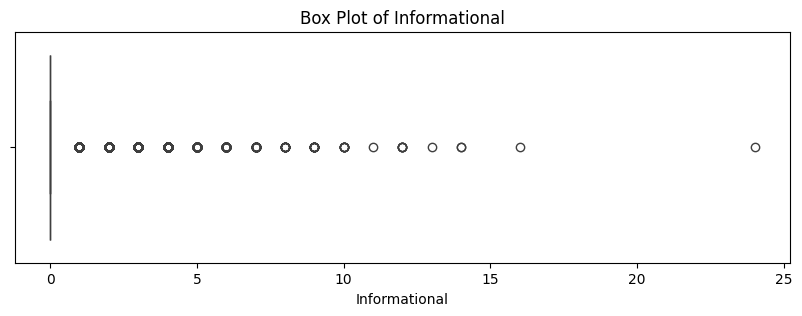

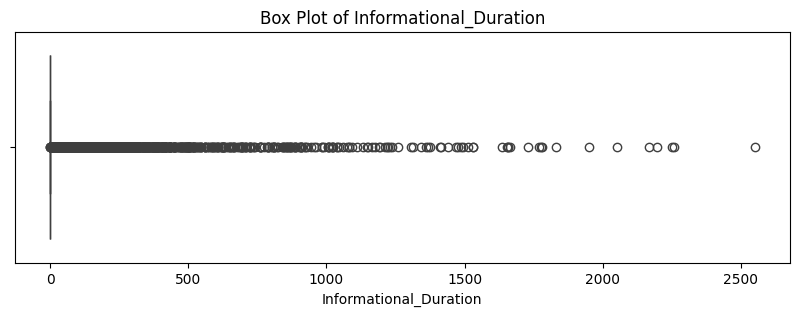

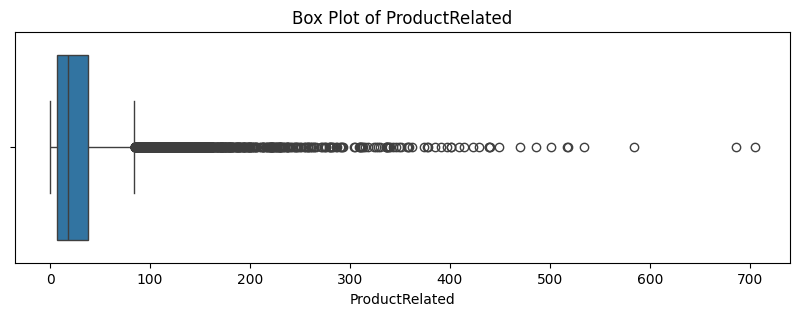

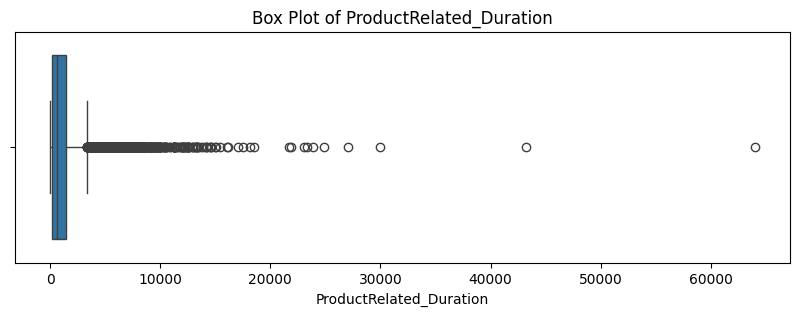

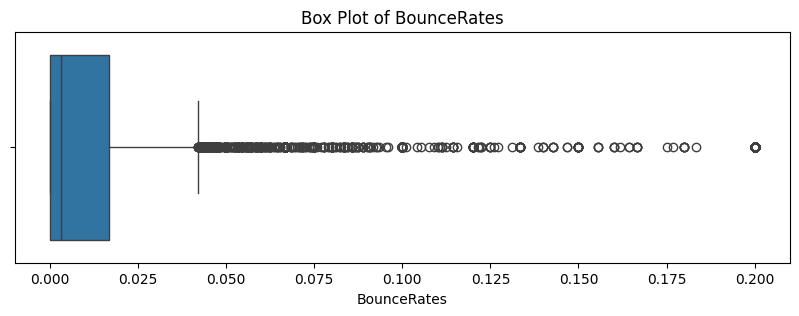

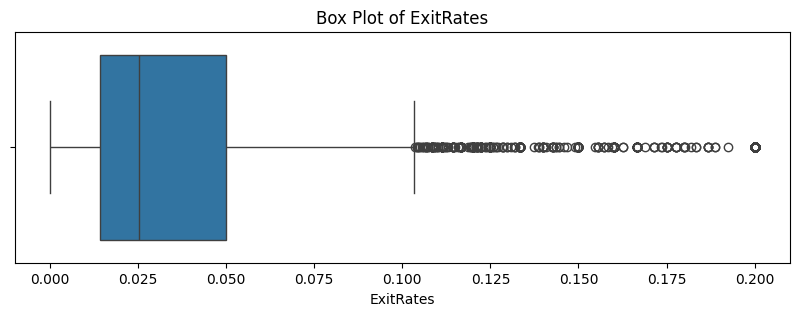

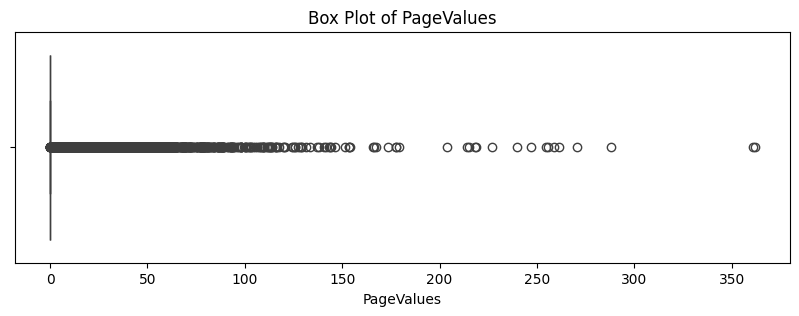

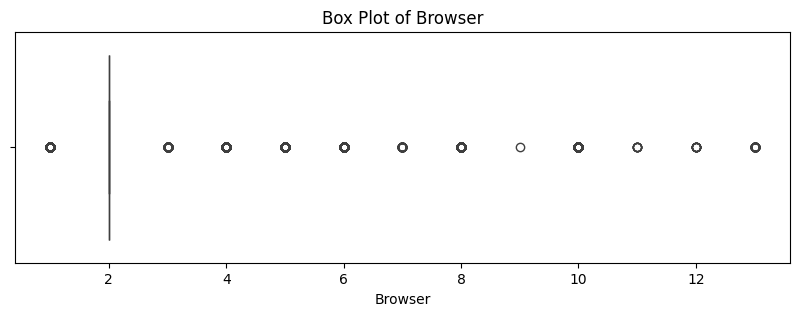

In [15]:
# Fitur numerik (tanpa target) & kolom yang layak dicek outlier
numeric_features = [c for c in df.select_dtypes(include="number").columns if c != TARGET]
outlier_cols = [c for c in numeric_features if df[c].nunique() > 10]
print("Fitur numerik       :", numeric_features)
print("Dicek outlier       :", outlier_cols)

# Boxplot untuk mendeteksi outlier (maks. 10 fitur pertama supaya output tidak terlalu panjang)
for feature in outlier_cols[:10]:
    plt.figure(figsize=(10, 3))
    sns.boxplot(x=df[feature])
    plt.title(f"Box Plot of {feature}")
    plt.show()

In [16]:
n_before = len(df)
df_before_outlier = df.copy()   # untuk perbandingan sebelum/sesudah

if OUTLIER_METHOD != "tidak" and len(outlier_cols) > 0:
    Q1 = df[outlier_cols].quantile(0.25)
    Q3 = df[outlier_cols].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    if OUTLIER_METHOD == "hapus":
        # simpan hanya baris yang tidak mengandung outlier pada kolom numerik
        condition = ~((df[outlier_cols] < lower) | (df[outlier_cols] > upper)).any(axis=1)
        df = df.loc[condition].copy()
    elif OUTLIER_METHOD == "batas":
        # ganti outlier dengan nilai batas terdekat (tidak ada data yang hilang)
        df[outlier_cols] = df[outlier_cols].clip(lower=lower, upper=upper, axis=1)

removed = n_before - len(df)
print(f"Metode: {OUTLIER_METHOD} | baris sebelum: {n_before} | sesudah: {len(df)} | terhapus: {removed} ({removed/n_before*100:.1f}%)")
if removed / n_before > 0.30:
    print("⚠️ Lebih dari 30% data terhapus. Sebaiknya ubah OUTLIER_METHOD menjadi 'batas' atau 'tidak' di cell konfigurasi, lalu Run All lagi.")
if len(df) < 1000:
    print("⚠️ Jumlah data sekarang < 1000. Coba OUTLIER_METHOD = 'batas' agar jumlah data tetap utuh.")

Metode: tidak | baris sebelum: 12330 | sesudah: 12330 | terhapus: 0 (0.0%)


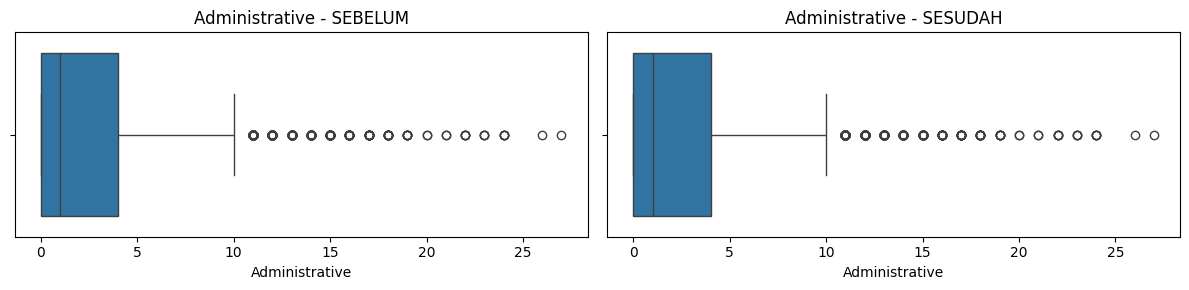

In [17]:
# Perbandingan sebelum & sesudah penanganan outlier (pada 1 fitur pertama)
if len(outlier_cols) > 0:
    f = outlier_cols[0]
    fig, ax = plt.subplots(1, 2, figsize=(12, 3))
    sns.boxplot(x=df_before_outlier[f], ax=ax[0]); ax[0].set_title(f"{f} - SEBELUM")
    sns.boxplot(x=df[f], ax=ax[1]);                ax[1].set_title(f"{f} - SESUDAH")
    plt.tight_layout(); plt.show()

### 4.5 Menangani Duplikasi Data

Data duplikat memengaruhi model, apalagi jika jumlahnya besar. `duplicated()` mengembalikan Series boolean (True = baris duplikat) dan `drop_duplicates()` menghapusnya.

In [18]:
duplicates = df.duplicated()
print("Jumlah baris duplikat:", duplicates.sum())
df[duplicates].head()

Jumlah baris duplikat: 125


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,1,1,1,3,Returning_Visitor,0,0
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,0,0
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Feb,3,2,3,3,Returning_Visitor,0,0
418,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,1,1,1,1,Returning_Visitor,1,0
456,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Mar,2,2,4,1,Returning_Visitor,0,0


In [19]:
df = df.drop_duplicates()
print("Dimensi setelah menghapus duplikat:", df.shape)

Dimensi setelah menghapus duplikat: (12205, 18)


## 5. Transformasi Data: Konversi Tipe Data (Encoding)

Model ML hanya bisa menerima input **numerik**, jadi data kategorikal harus di-*encode*:

| Teknik | Cara kerja | Kelebihan | Kekurangan |
|--------|-----------|-----------|------------|
| **One-Hot Encoding** | tiap kategori menjadi kolom biner 0/1 | tidak mengasumsikan urutan | jumlah kolom bertambah banyak |
| **Label Encoding** | tiap kategori diberi angka | tidak menambah kolom, hemat memori | mengasumsikan ada urutan antar kategori |

Di modul, kedua teknik dicoba agar terlihat perbedaannya, lalu dipilih **Label Encoding** untuk dilanjutkan.

In [20]:
# Kolom kategorikal (selain target)
category_features = [c for c in df.select_dtypes(exclude=["number", "bool"]).columns if c != TARGET]
print("Kolom kategorikal:", category_features)
df[category_features].head()

Kolom kategorikal: ['Month', 'VisitorType']


,Month,VisitorType
0,Feb,Returning_Visitor
1,Feb,Returning_Visitor
2,Feb,Returning_Visitor
3,Feb,Returning_Visitor
4,Feb,Returning_Visitor


### 5.1 One-Hot Encoding (untuk perbandingan)

In [21]:
df_one_hot = pd.get_dummies(df, columns=category_features)
print(f"Jumlah kolom sebelum one-hot: {df.shape[1]}  ->  sesudah one-hot: {df_one_hot.shape[1]}")
df_one_hot.head()

Jumlah kolom sebelum one-hot: 18  ->  sesudah one-hot: 29


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,...,False,False,False,False,False,False,False,False,False,True


### 5.2 Label Encoding (yang dipakai untuk pemodelan)

`LabelEncoder` hanya mengubah *isi* kolom sehingga jumlah kolom tidak berubah. Jika target klasifikasi berupa teks (misal "Ya"/"Tidak"), target juga ikut di-encode.

In [22]:
from sklearn.preprocessing import LabelEncoder

df_lencoder = df.copy()
label_encoders = {}

cols_to_encode = category_features + ([TARGET] if not pd.api.types.is_numeric_dtype(df[TARGET]) else [])
for col in cols_to_encode:
    le = LabelEncoder()
    df_lencoder[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le

if TARGET in label_encoders:
    print("Arti kode target:", dict(enumerate(label_encoders[TARGET].classes_)))

print("Dimensi data hasil encoding:", df_lencoder.shape)
df_lencoder.head()

Dimensi data hasil encoding: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,1,1,1,1,2,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,2,1,2,2,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,2,4,1,9,3,2,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,2,3,2,2,4,2,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,2,3,3,1,4,2,1,0


## 6. Exploratory Data Analysis (EDA)

EDA bertujuan memahami pola, anomali, dan struktur data lewat visualisasi dan statistik. Tahap ini sangat "bebas" — kamu boleh mengeksplorasi sebanyak mungkin.

### 6.1 Cek ulang missing value
Data harus sudah bersih sebelum dimodelkan.

In [23]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100
missing_data = pd.DataFrame({"Missing Values": missing_values, "Percentage": missing_percentage}) \
                 .sort_values(by="Missing Values", ascending=False)

print("Total missing value:", int(missing_values.sum()))
missing_data[missing_data["Missing Values"] > 0]

Total missing value: 0


,Missing Values,Percentage


### 6.2 Statistik deskriptif

In [24]:
df_lencoder.describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
count,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000,12205.000000
mean,2.338878,81.646331,0.508726,34.825454,32.045637,1206.982457,0.020370,0.041466,5.949574,0.061942,5.168046,2.124211,2.357804,3.153298,4.073904,1.715936,0.234248,0.156329
std,3.330436,177.491845,1.275617,141.424807,44.593649,1919.601400,0.045255,0.046163,18.653671,0.199666,2.374071,0.906823,1.710114,2.402340,4.016654,0.693425,0.423545,0.363182
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,8.000000,193.000000,0.000000,0.014231,0.000000,0.000000,5.000000,2.000000,2.000000,1.000000,2.000000,2.000000,0.000000,0.000000
50%,1.000000,9.000000,0.000000,0.000000,18.000000,608.942857,0.002899,0.025000,0.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,2.000000,0.000000,0.000000
75%,4.000000,94.700000,0.000000,0.000000,38.000000,1477.154762,0.016667,0.048529,0.000000,0.000000,7.000000,3.000000,2.000000,4.000000,4.000000,2.000000,0.000000,0.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,9.000000,8.000000,13.000000,9.000000,20.000000,2.000000,1.000000,1.000000


### 6.3 Histogram seluruh variabel
Histogram menunjukkan sebaran nilai tiap kolom (maksimal 20 kolom pertama agar tidak terlalu panjang).

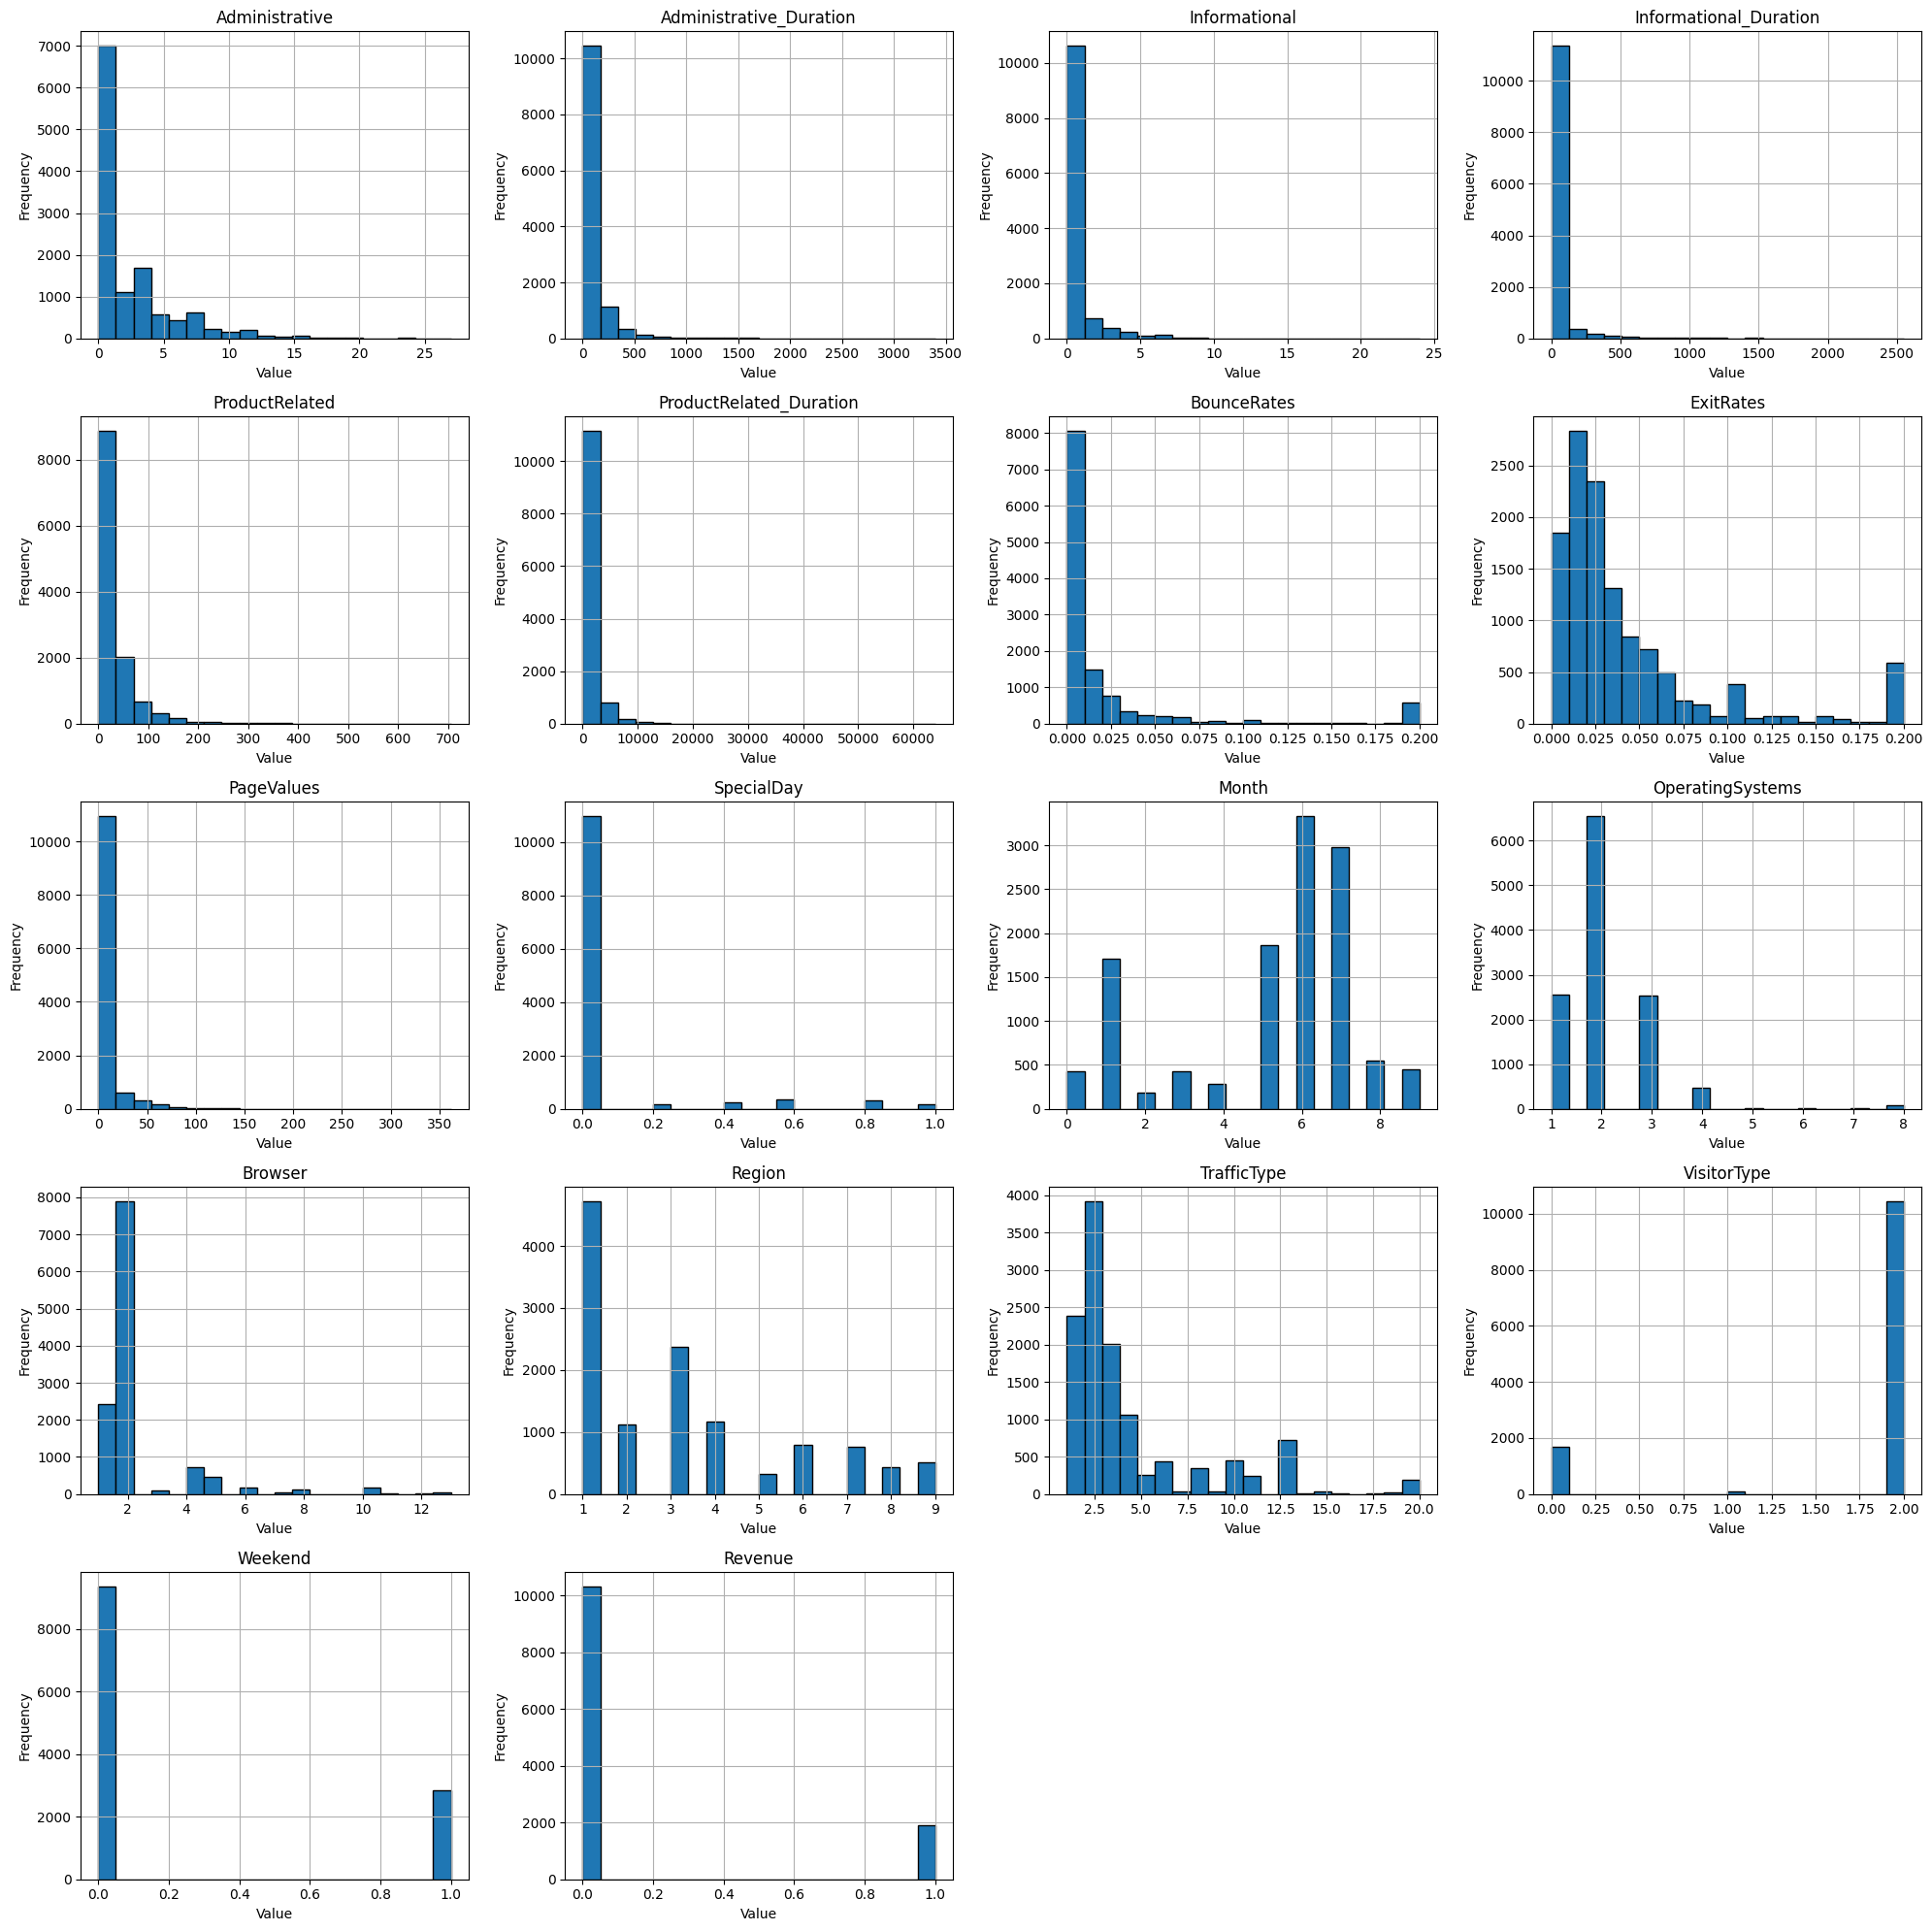

In [25]:
cols_hist = list(df_lencoder.columns[:20])
num_vars = len(cols_hist)
n_cols = 4
n_rows = -(-num_vars // n_cols)          # ceiling division

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = np.array(axes).flatten()

for i, column in enumerate(cols_hist):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor="black")
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 6.4 Matriks korelasi
Warna menunjukkan kekuatan hubungan antar variabel: **+1** korelasi positif sempurna, **−1** negatif sempurna, **0** tidak ada hubungan linear.

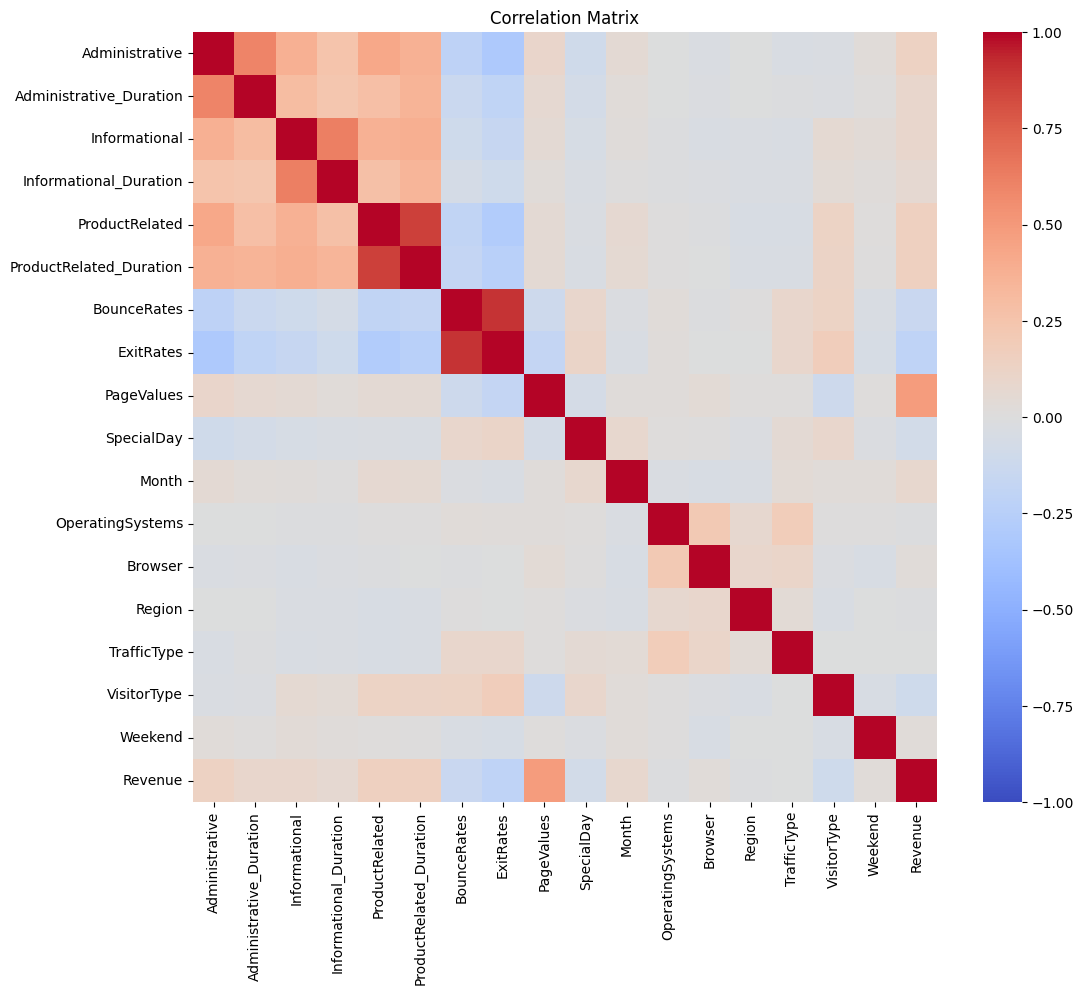

In [26]:
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()
sns.heatmap(correlation_matrix, annot=False, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

### 6.5 Korelasi setiap fitur terhadap target
Fitur dengan korelasi tinggi terhadap target biasanya lebih berpengaruh pada prediksi.

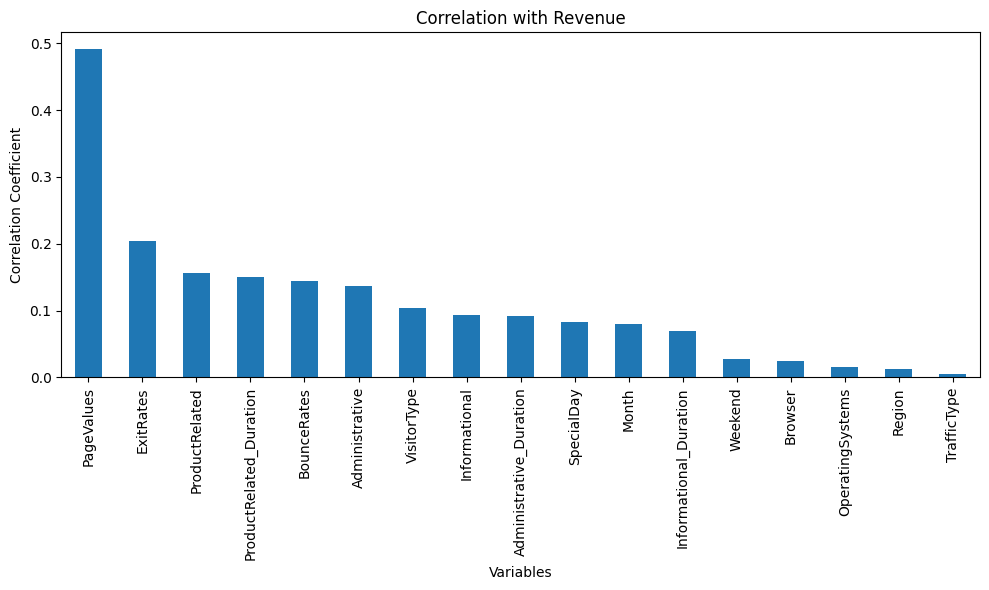

10 fitur paling berkorelasi dengan target:
PageValues                 0.491894
ExitRates                  0.204320
ProductRelated             0.156042
ProductRelated_Duration    0.150077
BounceRates                0.145091
Administrative             0.136330
VisitorType                0.103469
Informational              0.093626
Administrative_Duration    0.091768
SpecialDay                 0.083601
Name: Revenue, dtype: float64


In [27]:
target_corr = df_lencoder.corr()[TARGET].drop(TARGET).fillna(0)
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind="bar")
plt.title(f"Correlation with {TARGET}")
plt.xlabel("Variables")
plt.ylabel("Correlation Coefficient")
plt.tight_layout()
plt.show()

print("10 fitur paling berkorelasi dengan target:")
print(target_corr_sorted.head(10))

### 6.6 Distribusi 5 fitur paling berpengaruh

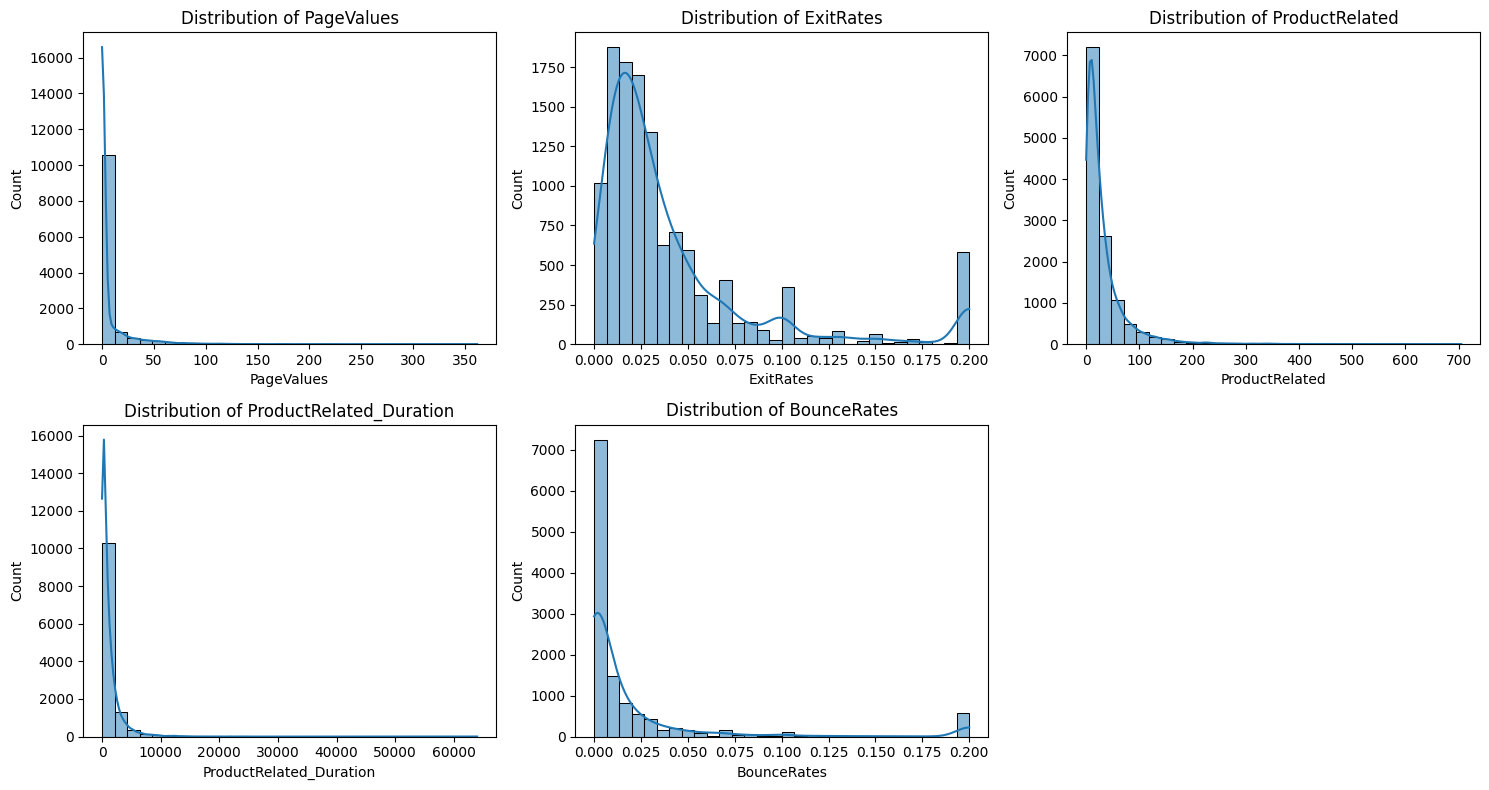

In [28]:
columns_to_plot = list(target_corr_sorted.head(5).index)

plt.figure(figsize=(15, 8))
for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f"Distribution of {column}")
plt.tight_layout()
plt.show()

### 6.7 (Opsional) Seleksi fitur berdasarkan korelasi
Jika `CORR_THRESHOLD` > 0, fitur dengan korelasi (absolut) di bawah batas akan dibuang. Nilai default `0.0` berarti semua fitur dipakai.

In [29]:
if CORR_THRESHOLD > 0:
    drop_low = target_corr_sorted[target_corr_sorted < CORR_THRESHOLD].index.tolist()
    df_lencoder = df_lencoder.drop(columns=drop_low)
    numeric_features = [c for c in numeric_features if c not in drop_low]
    print("Fitur dibuang karena korelasi rendah:", drop_low)
else:
    print("Seleksi fitur tidak dipakai (CORR_THRESHOLD = 0.0). Semua fitur dipertahankan.")
print("Dimensi data final:", df_lencoder.shape)

Seleksi fitur tidak dipakai (CORR_THRESHOLD = 0.0). Semua fitur dipertahankan.
Dimensi data final: (12205, 18)


## 7. Data Splitting

Data dibagi menjadi **training set** (untuk melatih model) dan **test set** (untuk menguji model pada data yang belum pernah dilihat). Tujuannya: menghindari *overfitting*, evaluasi akurat, dan validasi yang adil.

- Rasio umum: **80:20** atau 70:30.
- `X` = fitur (semua kolom kecuali target), `y` = target.
- `random_state` dikunci supaya hasil reproducible.
- Untuk **klasifikasi**, dipakai `stratify=y` agar proporsi kelas di train & test sama (penting jika data tidak seimbang).

> **Urutan preprocessing:** imputasi missing value, encoding, dan pembersihan sudah dilakukan **sebelum** splitting. Sedangkan **standardisasi/normalisasi dilakukan sesudah splitting** (hanya di-*fit* pada data latih) untuk menghindari *data leakage*.

In [30]:
from sklearn.model_selection import train_test_split

# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=[TARGET])
y = df_lencoder[TARGET]

stratify = y if (TASK == "klasifikasi" and y.value_counts().min() >= 2) else None

# membagi dataset menjadi training dan testing
x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=stratify
)

print("Jumlah data       :", len(X))
print("Jumlah data latih :", len(x_train))
print("Jumlah data test  :", len(x_test))

Jumlah data       : 12205
Jumlah data latih : 9764
Jumlah data test  : 2441


## 8. Normalisasi & Standardisasi

Fitur dengan skala berbeda jauh (mis. gaji jutaan vs umur puluhan) dapat membuat model bias ke fitur berskala besar.

| Teknik | Hasil | Cocok untuk |
|--------|-------|-------------|
| **Normalisasi** (`MinMaxScaler`) | skala 0–1 | model berbasis jarak (KNN, K-Means), data tidak normal |
| **Standardisasi** (`StandardScaler`, Z-score) | mean ≈ 0, std ≈ 1 | regresi linear/logistik, data mendekati normal |

Fungsi: `fit()` menghitung parameter (min/max atau mean/std), `transform()` menerapkannya.

### 8.1 Demo konsep dari modul (data gaji & umur)

In [31]:
from sklearn.preprocessing import MinMaxScaler
from sklearn import preprocessing

data = [[12000000, 33], [35000000, 45], [4000000, 23], [6500000, 26], [9000000, 29]]

# Normalisasi (Min-Max) -> skala 0 sampai 1
scaler_demo = MinMaxScaler()
scaler_demo.fit(data)
print("Hasil Normalisasi (MinMaxScaler):")
print(scaler_demo.transform(data))

# Standardisasi (Z-score) -> mean 0, std 1
scaler_demo2 = preprocessing.StandardScaler().fit(data)
print("\nHasil Standardisasi (StandardScaler):")
print(scaler_demo2.transform(data))

Hasil Normalisasi (MinMaxScaler):
[[0.25806452 0.45454545]
 [1.         1.        ]
 [0.         0.        ]
 [0.08064516 0.13636364]
 [0.16129032 0.27272727]]

Hasil Standardisasi (StandardScaler):
[[-0.11638732  0.23521877]
 [ 1.94277296  1.80334389]
 [-0.83261698 -1.07155217]
 [-0.60879521 -0.67952089]
 [-0.38497344 -0.28748961]]


### 8.2 Standardisasi pada dataset kita
Hanya fitur **numerik asli** yang distandardisasi (kolom hasil label encoding & target tidak ikut). Scaler di-*fit* hanya pada **data latih**, lalu diterapkan ke data uji.

In [32]:
from sklearn.preprocessing import StandardScaler

scale_cols = [c for c in numeric_features if c in x_train.columns]
x_train_before = x_train.copy()          # simpan untuk perbandingan

x_train = x_train.copy(); x_test = x_test.copy()
x_train[scale_cols] = x_train[scale_cols].astype(float)
x_test[scale_cols]  = x_test[scale_cols].astype(float)

scaler = StandardScaler()
if scale_cols:
    x_train[scale_cols] = scaler.fit_transform(x_train[scale_cols])   # fit hanya di data latih
    x_test[scale_cols]  = scaler.transform(x_test[scale_cols])        # test hanya transform

print("Kolom yang distandardisasi:", scale_cols)
x_train.head()

Kolom yang distandardisasi: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'Weekend']


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
3965,-0.699170,-0.464096,-0.396188,-0.243806,-0.556933,-0.427435,-0.136130,0.709434,-0.313824,-0.308279,6,-0.133833,0.944905,1.604519,-0.769896,2,1.801449
10906,-0.699170,-0.464096,-0.396188,-0.243806,-0.226587,-0.443673,-0.350789,-0.405878,-0.313824,-0.308279,7,-0.133833,-0.212620,-0.890813,-0.769896,2,1.801449
9131,-0.699170,-0.464096,-0.396188,-0.243806,-0.534910,-0.288124,-0.450963,-0.356714,-0.313824,-0.308279,7,4.251232,-0.212620,-0.890813,-0.275681,2,-0.555109
11713,0.795291,0.150730,7.596332,3.414440,5.477388,7.103150,-0.263661,-0.255105,-0.313824,-0.308279,1,-0.133833,-0.212620,-0.890813,-0.522788,2,-0.555109
3709,-0.699170,-0.464096,-0.396188,-0.243806,-0.623002,-0.581567,-0.450963,0.184086,-0.313824,1.705797,6,-0.133833,0.944905,-0.474924,-0.028573,2,-0.555109


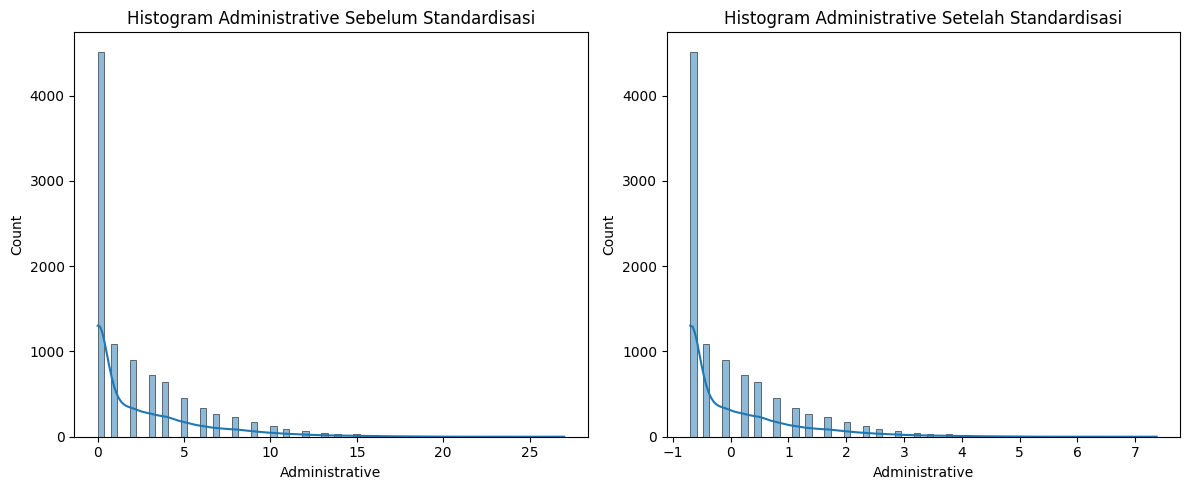

In [33]:
# Perbandingan histogram sebelum & sesudah standardisasi (1 fitur pertama)
if scale_cols:
    f = scale_cols[0]
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    sns.histplot(x_train_before[f], kde=True)
    plt.title(f"Histogram {f} Sebelum Standardisasi")
    plt.subplot(1, 2, 2)
    sns.histplot(x_train[f], kde=True)
    plt.title(f"Histogram {f} Setelah Standardisasi")
    plt.tight_layout(); plt.show()

## 9. Pembangunan Model (Modelling)

Model **belajar** dari data latih lewat `.fit(x_train, y_train)`. Pada latihan ini tidak ada hyperparameter tuning, jadi tiap algoritma memakai konfigurasi dasarnya.

- **Regresi** → LARS, Linear Regression, Gradient Boosting Regressor (sesuai modul)
- **Klasifikasi** → Decision Tree (`clf`, sesuai modul), Logistic Regression, Random Forest

Cell di bawah otomatis menyesuaikan dengan `TASK` yang terdeteksi.

In [34]:
models = {}

if TASK == "regresi":
    # Model 1: Least Angle Regression
    from sklearn import linear_model
    lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

    # Model 2: Linear Regression
    from sklearn.linear_model import LinearRegression
    LR = LinearRegression().fit(x_train, y_train)

    # Model 3: Gradient Boosting Regressor
    from sklearn.ensemble import GradientBoostingRegressor
    GBR = GradientBoostingRegressor(random_state=184)
    GBR.fit(x_train, y_train)

    models = {"Lars": lars, "Linear Regression": LR, "GradientBoostingRegressor": GBR}

else:
    # Model 1: Decision Tree (classifier, disingkat clf)
    from sklearn import tree
    clf = tree.DecisionTreeClassifier(random_state=RANDOM_STATE).fit(x_train, y_train)

    # Model 2: Logistic Regression
    from sklearn.linear_model import LogisticRegression
    LogReg = LogisticRegression(max_iter=1000).fit(x_train, y_train)

    # Model 3: Random Forest
    from sklearn.ensemble import RandomForestClassifier
    RF = RandomForestClassifier(random_state=RANDOM_STATE).fit(x_train, y_train)

    models = {"Decision Tree": clf, "Logistic Regression": LogReg, "Random Forest": RF}

print("Model yang berhasil dilatih:", list(models.keys()))

Model yang berhasil dilatih: ['Decision Tree', 'Logistic Regression', 'Random Forest']


## 10. Evaluasi Model

Model diuji pada **data uji** (`x_test`) yang tidak digunakan saat pelatihan. `.predict()` menghasilkan prediksi, lalu dibandingkan dengan nilai asli (`y_test`).

**Regresi:**
- **MAE** – rata-rata selisih absolut prediksi vs aktual (makin kecil makin baik)
- **MSE** – rata-rata kuadrat selisih, lebih sensitif terhadap outlier (makin kecil makin baik)
- **R²** – proporsi varians target yang dapat dijelaskan model (makin dekat 1 makin baik)

**Klasifikasi:**
- **Accuracy** – proporsi prediksi benar
- **Precision, Recall, F1-score** – dihitung rata-rata berbobot (*weighted*) agar aman untuk multi-kelas

In [35]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score)

df_results = pd.DataFrame()
predictions = {}

for name, model in models.items():
    pred = model.predict(x_test)
    predictions[name] = pred
    if TASK == "regresi":
        df_results.loc[name, "MAE"] = mean_absolute_error(y_test, pred)
        df_results.loc[name, "MSE"] = mean_squared_error(y_test, pred)
        df_results.loc[name, "R2"]  = r2_score(y_test, pred)
    else:
        df_results.loc[name, "Accuracy"]  = accuracy_score(y_test, pred)
        df_results.loc[name, "Precision"] = precision_score(y_test, pred, average="weighted", zero_division=0)
        df_results.loc[name, "Recall"]    = recall_score(y_test, pred, average="weighted", zero_division=0)
        df_results.loc[name, "F1-score"]  = f1_score(y_test, pred, average="weighted", zero_division=0)

df_results

,Accuracy,Precision,Recall,F1-score
Decision Tree,0.854158,0.860235,0.854158,0.856934
Logistic Regression,0.877100,0.863188,0.877100,0.859981
Random Forest,0.902089,0.895693,0.902089,0.896951


Model terbaik: Random Forest  (F1-score = 0.8970)


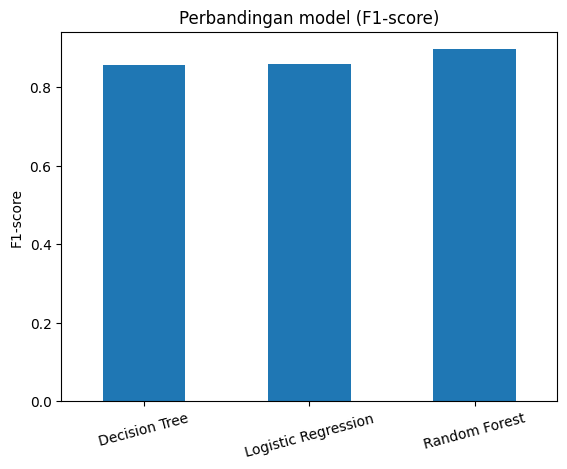

In [36]:
# Model terbaik: R2 tertinggi (regresi) / F1-score tertinggi (klasifikasi)
metric_utama = "R2" if TASK == "regresi" else "F1-score"
best_name = df_results[metric_utama].idxmax()
best_model = models[best_name]
print(f"Model terbaik: {best_name}  ({metric_utama} = {df_results.loc[best_name, metric_utama]:.4f})")

df_results[metric_utama].plot(kind="bar", title=f"Perbandingan model ({metric_utama})", rot=15)
plt.ylabel(metric_utama)
plt.show()

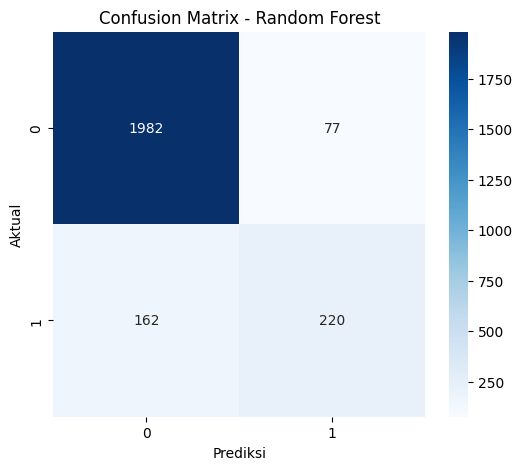

              precision    recall  f1-score   support

           0       0.92      0.96      0.94      2059
           1       0.74      0.58      0.65       382

    accuracy                           0.90      2441
   macro avg       0.83      0.77      0.80      2441
weighted avg       0.90      0.90      0.90      2441



In [37]:
pred_best = predictions[best_name]

if TASK == "regresi":
    # Grafik nilai aktual vs prediksi
    plt.figure(figsize=(6, 6))
    plt.scatter(y_test, pred_best, alpha=0.5)
    lims = [min(y_test.min(), pred_best.min()), max(y_test.max(), pred_best.max())]
    plt.plot(lims, lims, "r--")
    plt.xlabel("Nilai Aktual"); plt.ylabel("Nilai Prediksi")
    plt.title(f"Aktual vs Prediksi - {best_name}")
    plt.show()
else:
    from sklearn.metrics import confusion_matrix, classification_report
    labels = sorted(y.unique())
    names = [str(label_encoders[TARGET].classes_[i]) if TARGET in label_encoders else str(i) for i in labels]

    cm = confusion_matrix(y_test, pred_best, labels=labels)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names)
    plt.xlabel("Prediksi"); plt.ylabel("Aktual")
    plt.title(f"Confusion Matrix - {best_name}")
    plt.show()

    print(classification_report(y_test, pred_best, labels=labels, target_names=names, zero_division=0))

## 11. Cross Validation (K-Fold)

Evaluasi dengan satu kali `train_test_split` bisa bervariasi tergantung pembagian datanya. **K-Fold Cross Validation** membagi data menjadi *K* lipatan; tiap lipatan dipakai sekali sebagai data uji, sisanya sebagai data latih. Hasil akhirnya adalah rata-rata dari semua lipatan, sehingga evaluasi lebih stabil.

`cross_val_score(model, X, y, cv=5)` mengembalikan array skor tiap fold (klasifikasi = akurasi, regresi = R²). Pada klasifikasi, pembagian otomatis *stratified*. Untuk menghindari kebocoran data, cross validation dijalankan pada **data latih** saja.

> Patokan dari modul: jika skor tiap fold konsisten dan tinggi (≈ 0.85–0.99), model dapat dikatakan baik.

In [38]:
from sklearn.model_selection import cross_val_score

scoring = "r2" if TASK == "regresi" else "accuracy"
cv_results = pd.DataFrame()

for name, model in models.items():
    scores = cross_val_score(model, x_train, y_train, cv=5, scoring=scoring)
    print(f"{name:28s} skor tiap fold: {np.round(scores, 4)}")
    cv_results.loc[name, "Mean"] = scores.mean()
    cv_results.loc[name, "Std"]  = scores.std()

print(f"\nMetrik: {scoring}")
cv_results

Decision Tree                skor tiap fold: [0.871  0.8418 0.8669 0.8505 0.854 ]
Logistic Regression          skor tiap fold: [0.8868 0.8858 0.8853 0.8802 0.8842]
Random Forest                skor tiap fold: [0.9104 0.8971 0.9027 0.9002 0.9032]

Metrik: accuracy


,Mean,Std
Decision Tree,0.856821,0.010728
Logistic Regression,0.884474,0.002305
Random Forest,0.902704,0.004415


## 12. Menyimpan Model

Model yang sudah dilatih disimpan ke file agar bisa dipakai lagi (misalnya di produksi) tanpa melatih ulang.
- **joblib** → disarankan untuk model scikit-learn
- **pickle** → modul standar Python

In [39]:
import joblib
import pickle

# Simpan model terbaik dengan joblib
joblib.dump(best_model, "model_terbaik.joblib")

# Simpan model terbaik dengan pickle
with open("model_terbaik.pkl", "wb") as file:
    pickle.dump(best_model, file)

# Simpan juga komponen preprocessing agar data baru bisa diproses dengan cara yang sama
preprocessing_bundle = {
    "fitur": list(X.columns),
    "kolom_scaling": scale_cols,
    "scaler": scaler,
    "label_encoders": label_encoders,
    "target": TARGET,
    "task": TASK,
}
joblib.dump(preprocessing_bundle, "preprocessing.joblib")

print(f"Tersimpan: model_terbaik.joblib, model_terbaik.pkl, preprocessing.joblib  (model: {best_name})")

Tersimpan: model_terbaik.joblib, model_terbaik.pkl, preprocessing.joblib  (model: Random Forest)


### 12.1 Uji: muat kembali model & prediksi

In [40]:
model_load = joblib.load("model_terbaik.joblib")
contoh = x_test.head(5)
hasil = pd.DataFrame({"Aktual": y_test.head(5).values, "Prediksi": model_load.predict(contoh)})
hasil

,Aktual,Prediksi
0,0,0
1,0,0
2,1,1
3,0,1
4,0,0


## 13. Kesimpulan

In [41]:
print("=" * 60)
print("RINGKASAN HASIL PROYEK")
print("=" * 60)
print(f"Dataset              : {FILE_PATH}")
print(f"Jumlah data awal     : {df_raw.shape[0]} baris, {df_raw.shape[1]} kolom")
print(f"Jumlah data akhir    : {df_lencoder.shape[0]} baris, {df_lencoder.shape[1]} kolom (setelah cleaning)")
print(f"Target               : {TARGET}  ({TASK})")
print(f"Data latih / uji     : {len(x_train)} / {len(x_test)}")
print(f"Model terbaik        : {best_name}")
print(f"{metric_utama:20s} : {df_results.loc[best_name, metric_utama]:.4f}")
print(f"Rata-rata CV ({scoring}) : {cv_results.loc[best_name, 'Mean']:.4f} (± {cv_results.loc[best_name, 'Std']:.4f})")
print("=" * 60)
df_results

RINGKASAN HASIL PROYEK
Dataset              : online_shoppers_intention.csv
Jumlah data awal     : 12330 baris, 18 kolom
Jumlah data akhir    : 12205 baris, 18 kolom (setelah cleaning)
Target               : Revenue  (klasifikasi)
Data latih / uji     : 9764 / 2441
Model terbaik        : Random Forest
F1-score             : 0.8970
Rata-rata CV (accuracy) : 0.9027 (± 0.0044)


,Accuracy,Precision,Recall,F1-score
Decision Tree,0.854158,0.860235,0.854158,0.856934
Logistic Regression,0.877100,0.863188,0.877100,0.859981
Random Forest,0.902089,0.895693,0.902089,0.896951
